# 04 · Models

Three steps, in the order the team agreed: screen every feature set with one untuned model, tune
only the winner with Optuna, then calibrate. Nothing is selected on a test set at any point.
Validation decides; the scaffold test set and the plant holdout are read once at the end.

**Two numbers are reported throughout and neither is dropped.** The scaffold test set is the
evaluation the repo settled on. The plant holdout is the set the deliverable is actually drawn
from, and 03 showed it sits much further from training (median nearest Tanimoto 0.39 to 0.47
against 0.67 to 0.70 for the scaffold test set). They answer different questions and the gap
between them is a result, not a discrepancy.

**The headline metric is precision at the head of the ranking**, not AUROC. The cost in this
project is a wasted synthesis, so what matters is the share of genuine actives among the handful of
compounds that would actually be made.

**Output.** `data/processed/04_models_<organism>.pkl` and scored predictions for 05. Figures `04_*`.

Code: `pipeline/models.py`, `pipeline/featureset.py`.

## 0. Settings

In [1]:
import hashlib
import json
import os
import pickle
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "notebooks"))
from pipeline import curation, data, featureset, ledger, models, viz

viz.use_style()
pd.set_option("display.width", 220)

CONFIG = {
    "pathogens": curation.PATHOGENS,
    "feature_sets": ["morgan", "descriptors", "hybrid"],
    "screen_models": ["random_forest", "gradient_boosting"],
    "screen_seeds": [0, 1, 2],
    "optuna_trials": int(os.environ.get("ETHNOHACK_TRIALS", 30)),
    "retune": os.environ.get("ETHNOHACK_RETUNE", "0") == "1",
    "search_space": "rf:n_estimators=200-700;min_samples_leaf=1-8;max_features=0.05-0.6",
    "calibration": "Platt (sigmoid) on the validation partition, model frozen",
    "recall_floor": 0.40,
    "threshold_um": 32.0,
    "bootstrap_repeats": 2000,
    "selection_rule": "validation AUROC, averaged over seeds; test sets never consulted",
    "seed": 0,
}
pd.Series(CONFIG, name="value").to_frame()

,value
pathogens,"[Staphylococcus aureus, Escherichia coli, Myco..."
feature_sets,"[morgan, descriptors, hybrid]"
screen_models,"[random_forest, gradient_boosting]"
screen_seeds,"[0, 1, 2]"
optuna_trials,30
retune,False
search_space,rf:n_estimators=200-700;min_samples_leaf=1-8;m...
calibration,"Platt (sigmoid) on the validation partition, m..."
recall_floor,0.4
threshold_um,32.0


## 1. Load what 03 built

Fingerprints are stored packed in the npz. They are only ever unpacked through
`featureset.matrices`, which checks the width: a packed array fed straight to a model trains on
byte values and still returns a plausible-looking number.

In [2]:
bundles, parts = {}, {}
for organism in CONFIG["pathogens"]:
    slug = curation.slug(organism)
    bundle = featureset.load(f"03_features_{slug}")
    frame = pd.read_parquet(data.PROCESSED / f"03_splits_{slug}.parquet")
    assert list(frame.skeleton) == list(bundle["skeleton"]), "split file and features disagree"
    bundles[organism] = bundle
    parts[organism] = {
        name: np.where(frame.partition.eq(name).to_numpy())[0]
        for name in ("train", "validation", "test", "plant")
    }
    sizes = {k: len(v) for k, v in parts[organism].items()}
    print(f"{organism}: {sizes}")

Staphylococcus aureus: {'train': 39736, 'validation': 8515, 'test': 8516, 'plant': 1424}
Escherichia coli: {'train': 29552, 'validation': 6337, 'test': 6336, 'plant': 874}
Mycobacterium tuberculosis: {'train': 15542, 'validation': 3337, 'test': 3337, 'plant': 691}


## 2. The screen

Two model families against three feature sets, three seeds each, scored on validation. Three seeds
is enough to say whether a gap is real: 03's single untuned fit put morgan and hybrid within 0.003
of each other, which is not a difference anyone should act on.

In [3]:
screen_rows = []
for organism in CONFIG["pathogens"]:
    bundle = bundles[organism]
    part = parts[organism]
    y = bundle["label"]
    matrices = featureset.matrices(bundle)
    weight = models.positive_weight(y[part["train"]])
    for feature_name in CONFIG["feature_sets"]:
        X = matrices[feature_name]
        for model_name in CONFIG["screen_models"]:
            for seed in CONFIG["screen_seeds"]:
                start = time.time()
                if model_name == "random_forest":
                    model = models.random_forest(seed=seed, n_estimators=200)
                else:
                    model = models.gradient_boosting(seed=seed, scale_pos_weight=weight)
                model.fit(X[part["train"]], y[part["train"]])
                scores = model.predict_proba(X[part["validation"]])[:, 1]
                plant_scores = model.predict_proba(X[part["plant"]])[:, 1]
                screen_rows.append({
                    "pathogen": organism,
                    "feature set": feature_name,
                    "model": model_name,
                    "seed": seed,
                    "validation AUROC": models.roc_auc_score(y[part["validation"]], scores),
                    "plant AUROC": models.roc_auc_score(y[part["plant"]], plant_scores),
                    "plant P@10%": models.precision_at(y[part["plant"]], plant_scores, 0.10),
                    "seconds": round(time.time() - start, 1),
                })
            last = screen_rows[-1]
            print(f"  {organism[:14]:14s} {feature_name:11s} {model_name:17s} "
                  f"{last['validation AUROC']:.3f}  ({last['seconds']:.0f}s)", flush=True)
    del matrices
screen = pd.DataFrame(screen_rows)
summary = screen.groupby(["pathogen", "feature set", "model"])["validation AUROC"].agg(
    mean="mean", sd="std"
)
display(summary.style.format({"mean": "{:.3f}", "sd": "{:.3f}"}))

artefact = screen.groupby(["pathogen", "feature set"])[["plant AUROC", "plant P@10%"]].mean()
display(artefact.style.format("{:.3f}"))
print("Artefact check: if the physicochemical block alone nearly matches the hybrid on the plant")
print("holdout, the model may be learning what a measured, drug-like compound looks like rather")
print("than what an active one looks like. A clear fingerprint advantage is the reassuring case.")

  Staphylococcus morgan      random_forest     0.872  (9s)


  Staphylococcus morgan      gradient_boosting 0.849  (8s)


  Staphylococcus descriptors random_forest     0.819  (2s)


  Staphylococcus descriptors gradient_boosting 0.800  (1s)


  Staphylococcus hybrid      random_forest     0.873  (8s)


  Staphylococcus hybrid      gradient_boosting 0.858  (9s)


... (9 outputs left out)

  Mycobacterium  descriptors gradient_boosting 0.707  (1s)


  Mycobacterium  hybrid      random_forest     0.838  (3s)


  Mycobacterium  hybrid      gradient_boosting 0.821  (4s)


Artefact check: if the physicochemical block alone nearly matches the hybrid on the plant
holdout, the model may be learning what a measured, drug-like compound looks like rather
than what an active one looks like. A clear fingerprint advantage is the reassuring case.


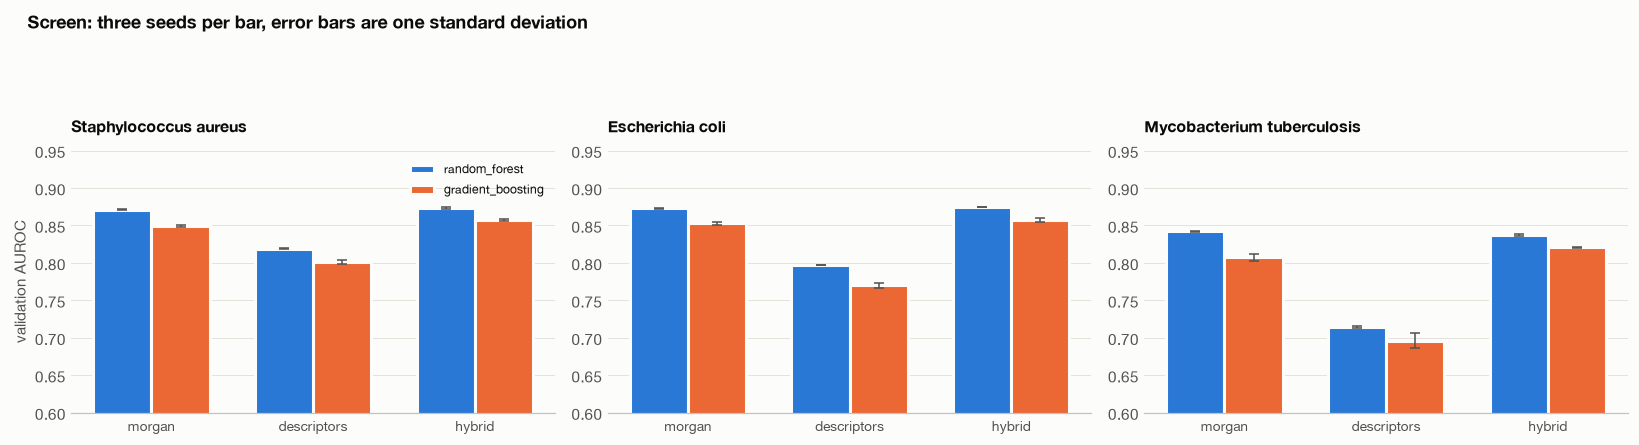

Staphylococcus aureus: hybrid + random_forest (0.874 +/- 0.001)
Escherichia coli: hybrid + random_forest (0.874 +/- 0.000)
Mycobacterium tuberculosis: morgan + random_forest (0.842 +/- 0.001)


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, organism in zip(axes, CONFIG["pathogens"]):
    block = summary.loc[organism]
    x = np.arange(len(CONFIG["feature_sets"]))
    width = 0.36
    for i, model_name in enumerate(CONFIG["screen_models"]):
        means = [block.loc[(f, model_name), "mean"] for f in CONFIG["feature_sets"]]
        sds = [block.loc[(f, model_name), "sd"] for f in CONFIG["feature_sets"]]
        ax.bar(x + (i - 0.5) * width, means, width=width, yerr=sds, capsize=3,
               color=viz.SERIES[i], edgecolor=viz.SURFACE, linewidth=2,
               error_kw=dict(ecolor=viz.INK_SECONDARY, lw=1), label=model_name)
    ax.set_xticks(x, CONFIG["feature_sets"], fontsize=9)
    ax.set_ylim(0.6, 0.95)
    ax.set_title(organism, fontsize=10.5)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("validation AUROC")
axes[0].legend(fontsize=8)
fig.suptitle("Screen: three seeds per bar, error bars are one standard deviation",
             x=0.02, ha="left", fontweight="bold")
viz.save(fig, "04_screen")
plt.show()

winners = {}
for organism in CONFIG["pathogens"]:
    block = summary.loc[organism].reset_index()
    best = block.sort_values("mean", ascending=False).iloc[0]
    winners[organism] = (best["feature set"], best["model"])
    print(f"{organism}: {best['feature set']} + {best['model']} "
          f"({best['mean']:.3f} +/- {best['sd']:.3f})")

## 3. Tuning the winner with Optuna

Optuna only, on the winning combination for each pathogen, maximising validation AUROC. The search
adapts to earlier trials rather than walking a grid, which is why the team chose it. The test sets
are not touched.

In [5]:
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)


def data_fingerprint(organism):
    bundle, part = bundles[organism], parts[organism]
    assignment = np.zeros(len(bundle["label"]), dtype=np.int8)
    for value, name in enumerate(("train", "validation", "test", "plant")):
        assignment[part[name]] = value
    digest = hashlib.sha256()
    digest.update(np.ascontiguousarray(bundle["label"]))
    digest.update(np.ascontiguousarray(assignment))
    return digest.hexdigest()[:12]


tuning_source = {}

studies, tuned = {}, {}
for organism in CONFIG["pathogens"]:
    feature_name, model_name = winners[organism]
    bundle = bundles[organism]
    part = parts[organism]
    y = bundle["label"]
    X = featureset.matrices(bundle)[feature_name]
    weight = models.positive_weight(y[part["train"]])
    Xtr, ytr = X[part["train"]], y[part["train"]]
    Xva, yva = X[part["validation"]], y[part["validation"]]

    def objective(trial):
        if model_name == "gradient_boosting":
            model = models.gradient_boosting(
                seed=CONFIG["seed"],
                scale_pos_weight=weight,
                n_estimators=trial.suggest_int("n_estimators", 200, 700, step=100),
                max_depth=trial.suggest_int("max_depth", 4, 10),
                learning_rate=trial.suggest_float("learning_rate", 0.02, 0.25, log=True),
                subsample=trial.suggest_float("subsample", 0.6, 1.0),
                colsample_bytree=trial.suggest_float("colsample_bytree", 0.3, 1.0),
                min_child_weight=trial.suggest_int("min_child_weight", 1, 12),
                reg_lambda=trial.suggest_float("reg_lambda", 0.5, 8.0, log=True),
            )
        else:
            model = models.random_forest(
                seed=CONFIG["seed"],
                n_estimators=trial.suggest_int("n_estimators", 200, 700, step=100),
                min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 8),
                max_features=trial.suggest_float("max_features", 0.05, 0.6),
            )
        model.fit(Xtr, ytr)
        return models.roc_auc_score(yva, model.predict_proba(Xva)[:, 1])

    cache = data.PROCESSED / f"04_tuning_{curation.slug(organism)}.json"
    signature = {"feature_set": feature_name, "model": model_name,
                 "trials": CONFIG["optuna_trials"], "seed": CONFIG["seed"],
                 "data": data_fingerprint(organism),
                 "space": CONFIG["search_space"]}
    if cache.exists() and not CONFIG["retune"]:
        saved = json.loads(cache.read_text())
        if saved.get("signature") == signature:
            tuned[organism] = saved["params"]
            studies[organism] = None
            tuning_source[organism] = "cache"
            print(f"{organism}: reusing cached tuning from {cache.name} "
                  f"(validation AUROC {saved['value']:.3f}, data {signature['data']}); "
                  "set ETHNOHACK_RETUNE=1 to search again",
                  flush=True)
            print(f"    {saved['params']}", flush=True)
            continue

    start = time.time()
    study = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=CONFIG["seed"]),
        study_name=f"{curation.slug(organism)}_{feature_name}_{model_name}",
    )
    study.optimize(objective, n_trials=CONFIG["optuna_trials"], show_progress_bar=False)
    studies[organism] = study
    tuned[organism] = study.best_params
    print(f"{organism}: {len(study.trials)} trials in {time.time() - start:.0f}s, "
          f"best validation AUROC {study.best_value:.3f} "
          f"(maximum over trials, not a performance estimate)", flush=True)
    print(f"    {study.best_params}", flush=True)
    tuning_source[organism] = "search"
    cache.write_text(json.dumps(
        {"signature": signature, "params": study.best_params, "value": study.best_value}, indent=2
    ))

Staphylococcus aureus: reusing cached tuning from 04_tuning_staphylococcus_aureus.json (validation AUROC 0.880, data 68ecd9738653); set ETHNOHACK_RETUNE=1 to search again


    {'n_estimators': 700, 'min_samples_leaf': 1, 'max_features': 0.10938954849632004}


Escherichia coli: reusing cached tuning from 04_tuning_escherichia_coli.json (validation AUROC 0.882, data 4767fd189bbe); set ETHNOHACK_RETUNE=1 to search again


    {'n_estimators': 700, 'min_samples_leaf': 1, 'max_features': 0.08498541635308984}


Mycobacterium tuberculosis: reusing cached tuning from 04_tuning_mycobacterium_tuberculosis.json (validation AUROC 0.846, data d87e8be8a7ed); set ETHNOHACK_RETUNE=1 to search again


    {'n_estimators': 600, 'min_samples_leaf': 2, 'max_features': 0.06026651430250143}


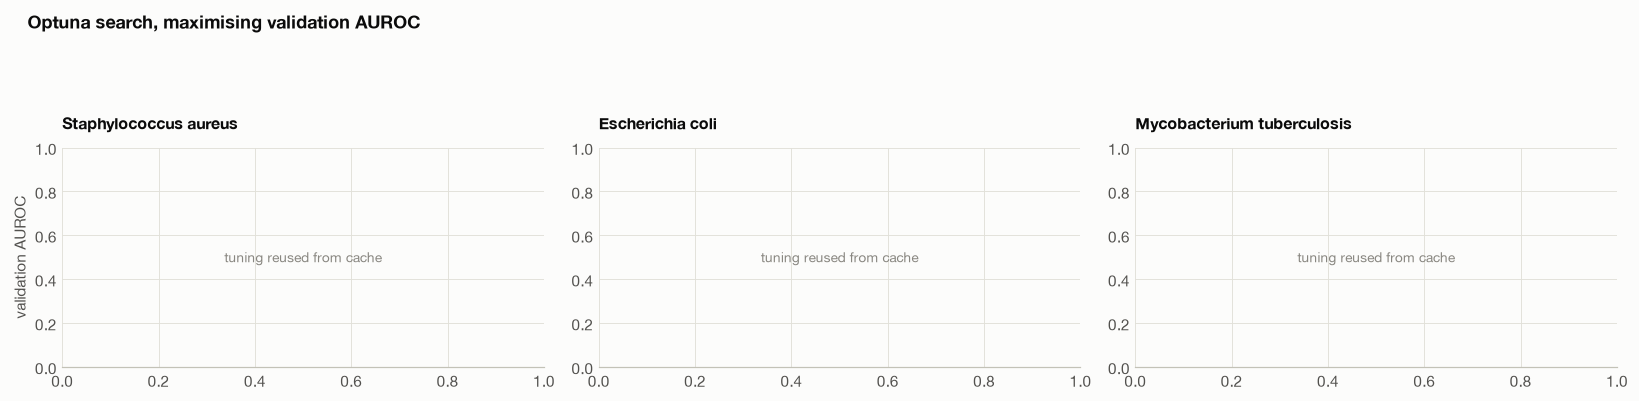

,feature set,model,untuned,tuned,gain
pathogen,,,,,
Staphylococcus aureus,hybrid,random_forest,0.874,0.880,0.007
Escherichia coli,hybrid,random_forest,0.874,0.882,0.008
Mycobacterium tuberculosis,morgan,random_forest,0.842,0.846,0.003


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
for ax, organism in zip(axes, CONFIG["pathogens"]):
    study = studies[organism]
    if study is None:
        ax.text(0.5, 0.5, "tuning reused from cache", ha="center", va="center",
                transform=ax.transAxes, fontsize=9, color=viz.MUTED)
        ax.set_title(organism, fontsize=10.5)
        continue
    values = [t.value for t in study.trials if t.value is not None]
    running = np.maximum.accumulate(values)
    ax.plot(range(1, len(values) + 1), values, marker="o", markersize=3.5, linewidth=0,
            color=viz.MUTED, label="trial")
    ax.plot(range(1, len(running) + 1), running, color=viz.SERIES[0], linewidth=2,
            label="best so far")
    baseline = summary.loc[(organism, *winners[organism]), "mean"]
    ax.axhline(baseline, color=viz.SERIES[1], linewidth=1.2, linestyle="--",
               label="untuned screen")
    ax.set_xlabel("trial")
    ax.set_title(organism, fontsize=10.5)
axes[0].set_ylabel("validation AUROC")
axes[0].legend(fontsize=8, loc="lower right")
fig.suptitle("Optuna search, maximising validation AUROC", x=0.02, ha="left", fontweight="bold")
viz.save(fig, "04_optuna")
plt.show()

def tuned_value(o):
    if studies[o] is not None:
        return studies[o].best_value
    return json.loads((data.PROCESSED / f"04_tuning_{curation.slug(o)}.json").read_text())["value"]


pd.DataFrame([
    {"pathogen": o, "feature set": winners[o][0], "model": winners[o][1],
     "untuned": summary.loc[(o, *winners[o]), "mean"], "tuned": tuned_value(o),
     "gain": tuned_value(o) - summary.loc[(o, *winners[o]), "mean"]}
    for o in CONFIG["pathogens"]
]).set_index("pathogen").style.format("{:.3f}", subset=["untuned", "tuned", "gain"])

### Did the search actually explore regularised models

The previous search space allowed `min_samples_leaf` only up to 8 and every arm chose 1, which is
an unregularised memoriser. Two explanations fit that: regularised models are genuinely worse
here, or the validation set rewarded memorising. The split changed in 03 precisely because the
second looked likely, so the search space is widened here to match: leaves up to 20, an explicit
depth limit, a lower floor on `max_features`, and a minimum split size.

The table below reads the trial records rather than taking the best value on trust. If the chosen
model is still unregularised after both changes, then regularisation really does not help on this
data and that is worth stating. If it is not, the previous answer was an artefact of where the
tuning signal came from.

In [7]:
trial_rows = []
for organism in CONFIG["pathogens"]:
    study = studies[organism]
    if study is None:
        trial_rows.append({"pathogen": organism, "trials": "reused from cache",
                           "chosen min_samples_leaf": tuned[organism].get("min_samples_leaf"),
                           "chosen max_depth": tuned[organism].get("max_depth"),
                           "chosen max_features": tuned[organism].get("max_features")})
        continue
    frame = pd.DataFrame([
        {**t.params, "value": t.value} for t in study.trials if t.value is not None
    ])
    regularised = frame[frame.min_samples_leaf >= 5]
    trial_rows.append({
        "pathogen": organism,
        "trials": len(frame),
        "trials with leaf >= 5": len(regularised),
        "best value, leaf = 1": float(frame[frame.min_samples_leaf == 1].value.max())
        if (frame.min_samples_leaf == 1).any() else np.nan,
        "best value, leaf >= 5": float(regularised.value.max()) if len(regularised) else np.nan,
        "chosen min_samples_leaf": tuned[organism].get("min_samples_leaf"),
        "chosen max_depth": tuned[organism].get("max_depth"),
        "chosen max_features": tuned[organism].get("max_features"),
    })
pd.DataFrame(trial_rows).set_index("pathogen")

,trials,chosen min_samples_leaf,chosen max_depth,chosen max_features
pathogen,,,,
Staphylococcus aureus,reused from cache,1,None,0.109390
Escherichia coli,reused from cache,1,None,0.084985
Mycobacterium tuberculosis,reused from cache,2,None,0.060267


## 3a. Does the tuning objective matter

The search above maximised validation AUROC, which pays equally for ordering compounds nobody
will ever synthesise. The metric the project actually cares about lives at the head of the
ranking, so the fair question is whether tuning for AUPRC instead would produce a better head.

The comparison is made on **P@10% only**, which is threshold-free. The threshold-dependent
precision was dropped from this table after inspection rather than reported: each arm picks its
threshold on validation, where roughly 55% of compounds are active, using uncalibrated scores, and
applying that cut-off to a holdout that is considerably less active flags almost nothing and returns a
precision of 1.000 on a handful of compounds. That is the degenerate case the recall floor exists
to prevent, and it is an artefact of the transfer rather than a result. The honest threshold
diagnostics, on calibrated scores with the flagged count and recall beside them, are in section 5a.

This is a **paired comparison at equal budget**, not a replacement search: the same trial count,
the same seeds and the same restricted search space for both objectives, scored on P@10% and on
precision at the recall floor. Restricting the space (fewer, smaller forests than the deliverable
search used) makes the comparison affordable, and it is applied identically to both arms, so it
cannot favour either. The deliverable model is still the full search above; this cell only answers
whether the objective changes the answer.

In [8]:
COMPARE_TRIALS = int(os.environ.get("ETHNOHACK_COMPARE_TRIALS", 15))
compare_cache = data.PROCESSED / "04_objective_comparison.json"

def restricted_forest(trial, seed):
    return models.random_forest(
        seed=seed,
        n_estimators=trial.suggest_int("n_estimators", 150, 300, step=50),
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 6),
        max_features=trial.suggest_float("max_features", 0.05, 0.20),
    )


def run_arm(organism, objective):
    feature_name, _ = winners[organism]
    bundle, part = bundles[organism], parts[organism]
    y = bundle["label"]
    X = featureset.matrix(bundle, feature_name)
    Xtr, ytr = X[part["train"]], y[part["train"]]
    Xva, yva = X[part["validation"]], y[part["validation"]]

    def objective_fn(trial):
        model = restricted_forest(trial, CONFIG["seed"]).fit(Xtr, ytr)
        p = model.predict_proba(Xva)[:, 1]
        return (models.roc_auc_score(yva, p) if objective == "auroc"
                else models.average_precision_score(yva, p))

    study = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=CONFIG["seed"]))
    study.optimize(objective_fn, n_trials=COMPARE_TRIALS, show_progress_bar=False)

    model = models.random_forest(seed=CONFIG["seed"], **study.best_params).fit(Xtr, ytr)
    out = {}
    for name in ("test", "plant"):
        scores = model.predict_proba(X[part[name]])[:, 1]
        truth = y[part[name]]
        threshold, _ = models.choose_threshold(
            yva, model.predict_proba(Xva)[:, 1], recall_floor=CONFIG["recall_floor"])
        out[name] = {
            "p_at_10pct": models.precision_at(truth, scores, 0.10),
            "precision_at_floor": models.threshold_metrics(truth, scores, threshold)["precision"],
            "auroc": models.roc_auc_score(truth, scores),
            "auprc": models.average_precision_score(truth, scores),
        }
    del X
    return study.best_params, out


if compare_cache.exists():
    comparison = json.loads(compare_cache.read_text())
    print(f"reusing the objective comparison from {compare_cache.name}")
else:
    comparison = {}
    for organism in CONFIG["pathogens"]:
        comparison[organism] = {}
        for objective in ("auroc", "auprc"):
            start = time.time()
            params, scores = run_arm(organism, objective)
            comparison[organism][objective] = {"params": params, "scores": scores}
            print(f"  {organism[:16]:16s} {objective} {COMPARE_TRIALS} trials "
                  f"in {time.time() - start:.0f}s, plant P@10% "
                  f"{scores['plant']['p_at_10pct']:.3f}", flush=True)
    compare_cache.write_text(json.dumps(comparison, indent=2))

rows = []
for organism, arms in comparison.items():
    for objective, payload in arms.items():
        for name, values in payload["scores"].items():
            rows.append({"pathogen": organism, "objective": objective,
                         "set": "scaffold test" if name == "test" else "plant holdout",
                         **values})
objective_table = pd.DataFrame(rows).set_index(["pathogen", "set", "objective"]).sort_index()
objective_table[["p_at_10pct", "auroc", "auprc"]].style.format("{:.3f}")

reusing the objective comparison from 04_objective_comparison.json


In [9]:
plant = objective_table.xs("plant holdout", level="set")
deltas = []
for organism in CONFIG["pathogens"]:
    if (organism, "auprc") not in plant.index or (organism, "auroc") not in plant.index:
        continue
    a, b = plant.loc[(organism, "auprc")], plant.loc[(organism, "auroc")]
    deltas.append({
        "pathogen": organism,
        "P@10% AUPRC-tuned": a.p_at_10pct,
        "P@10% AUROC-tuned": b.p_at_10pct,
        "difference": a.p_at_10pct - b.p_at_10pct,
        "precision at floor, difference": a.precision_at_floor - b.precision_at_floor,
    })
deltas = pd.DataFrame(deltas).set_index("pathogen")[
    ["P@10% AUPRC-tuned", "P@10% AUROC-tuned", "difference"]]
display(deltas.style.format("{:+.3f}", subset=["difference"])
        .format("{:.3f}", subset=["P@10% AUPRC-tuned", "P@10% AUROC-tuned"]))

wins = int((deltas.difference > 0).sum())
print(f"AUPRC-tuned beats AUROC-tuned on plant P@10% for {wins} of {len(deltas)} pathogens; "
      f"mean difference {deltas.difference.mean():+.3f}")

,P@10% AUPRC-tuned,P@10% AUROC-tuned,difference
pathogen,,,
Staphylococcus aureus,0.600,0.607,-0.007
Escherichia coli,0.443,0.443,+0.000
Mycobacterium tuberculosis,0.565,0.507,+0.058


AUPRC-tuned beats AUROC-tuned on plant P@10% for 1 of 3 pathogens; mean difference +0.017


**Verdict: the tuning objective does not move the head of the ranking at this data size.** One
inconsistent win in three, with the differences inside the spread we see between seeds elsewhere
in this notebook, is a negative result. The deliverable keeps the AUROC-tuned model from the full
search above, and no further search was run. Reporting this costs a paragraph and saved a
two-hour bet on a metric that turns out not to matter here; at a larger positive count it might.

## 4. Calibration

A tuned model ranks well and still reports probabilities that mean nothing in absolute terms.
Isotonic regression is fitted on the validation partition with the model frozen, so the fit never
touches either held-out set.

**What this can and cannot fix, measured rather than predicted.** Isotonic learns the mapping from
score to probability *at the validation base rate*. The plant holdout is considerably less active, and a mapping fitted at one prevalence does not transport to another. The table
below shows what that costs, and it differs by pathogen rather than going one way: for *E. coli*
the raw model genuinely over-predicted on plants and calibration fixed it, while for *S. aureus*
the raw scores were already close to the observed rate and for *M. tuberculosis* calibration barely
moved them. On two of the three, the plant Brier score gets slightly **worse** after calibration.

That is the prevalence shift showing through, not a failed fit, and it is a limitation to report
rather than tune away. It is also the first of two reasons this notebook leads with ranking metrics
rather than absolute probabilities.

**One more caveat on the calibrator.** The validation partition now does three jobs: choosing the
feature set and model, serving as the Optuna objective, and fitting the calibrator. None of that
touches a test set, so it is not leakage, but the calibrator is being fitted on scores the
hyperparameters were tuned to maximise. Calibration will therefore transfer slightly worse than
the validation Brier suggests, which the raw and calibrated Brier columns below will show.

**Calibration cannot change discrimination, and should not be expected to.** Both isotonic and
Platt are monotonic transformations of the score, so AUROC, AUPRC and every rank-based metric are
identical before and after. If the plant AUROC is unchanged to three decimals after recalibration,
that is the correct result rather than a sign the calibrator did nothing: what changes is what the
numbers *mean*, not what order they put compounds in.

**Why Platt rather than isotonic.** An earlier version of this notebook used isotonic regression,
which is a step function: it mapped 8,567 test compounds onto fewer than eighty distinct
probabilities, so a top-k cut was settled by hundreds of exact ties broken by row order rather
than by the model. AUROC was unaffected, since it averages over ties correctly, but precision at
the head of a ranking is exactly the metric that breaks.

Platt scaling fits a two-parameter sigmoid instead, which is strictly monotonic and injective, so
every distinct model score keeps a distinct probability and the ranking survives calibration
intact. That fixes the problem at its source rather than routing around it. Ranking is still done
on the raw score as a check, and the cell below asserts the two orderings agree; with a strictly
monotonic calibrator they must, and an assertion is cheaper than trusting that they do.

In [10]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator
from sklearn.metrics import brier_score_loss

fitted, calibrated, calibration_rows = {}, {}, []
for organism in CONFIG["pathogens"]:
    feature_name, model_name = winners[organism]
    bundle, part = bundles[organism], parts[organism]
    y = bundle["label"]
    X = featureset.matrices(bundle)[feature_name]
    weight = models.positive_weight(y[part["train"]])

    builder = models.gradient_boosting if model_name == "gradient_boosting" else models.random_forest
    extra = {"scale_pos_weight": weight} if model_name == "gradient_boosting" else {}
    model = builder(seed=CONFIG["seed"], **extra, **tuned[organism])
    model.fit(X[part["train"]], y[part["train"]])
    fitted[organism] = model

    wrapper = CalibratedClassifierCV(FrozenEstimator(model), method="sigmoid")
    wrapper.fit(X[part["validation"]], y[part["validation"]])
    calibrated[organism] = wrapper

    for name in ("test", "plant"):
        raw = model.predict_proba(X[part[name]])[:, 1]
        cal = wrapper.predict_proba(X[part[name]])[:, 1]
        calibration_rows.append({
            "pathogen": organism,
            "set": name,
            "observed active rate": float(np.mean(y[part[name]])),
            "mean predicted, raw": float(np.mean(raw)),
            "mean predicted, calibrated": float(np.mean(cal)),
            "Brier raw": brier_score_loss(y[part[name]], raw),
            "Brier calibrated": brier_score_loss(y[part[name]], cal),
        })
calibration_table = pd.DataFrame(calibration_rows).set_index(["pathogen", "set"])
calibration_table.style.format("{:.3f}")

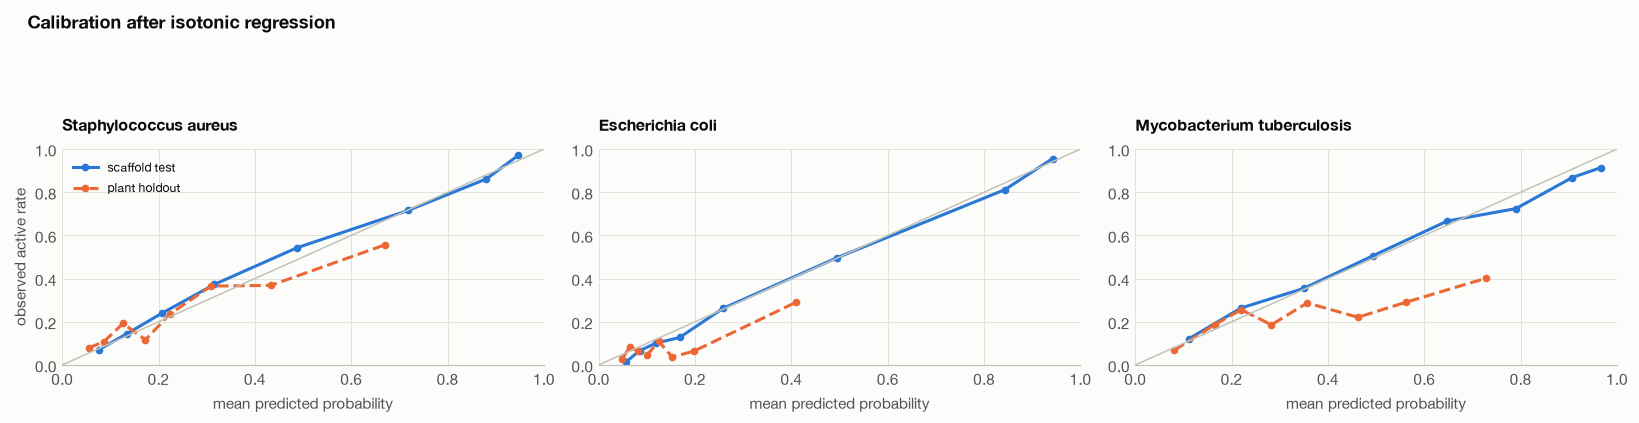

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, organism in zip(axes, CONFIG["pathogens"]):
    feature_name, _ = winners[organism]
    bundle, part = bundles[organism], parts[organism]
    X = featureset.matrices(bundle)[feature_name]
    y = bundle["label"]
    for i, (name, style) in enumerate([("test", "-"), ("plant", "--")]):
        scores = calibrated[organism].predict_proba(X[part[name]])[:, 1]
        truth = y[part[name]]
        bins = np.quantile(scores, np.linspace(0, 1, 9))
        bins = np.unique(bins)
        which = np.clip(np.digitize(scores, bins[1:-1]), 0, len(bins) - 2)
        xs, ys = [], []
        for b in range(len(bins) - 1):
            mask = which == b
            if mask.sum() >= 20:
                xs.append(scores[mask].mean())
                ys.append(truth[mask].mean())
        ax.plot(xs, ys, style, marker="o", markersize=4, color=viz.SERIES[i],
                label="scaffold test" if name == "test" else "plant holdout")
    ax.plot([0, 1], [0, 1], color=viz.AXIS, linewidth=1)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xlabel("mean predicted probability")
    ax.set_title(organism, fontsize=10.5)
axes[0].set_ylabel("observed active rate")
axes[0].legend(fontsize=8)
fig.suptitle("Calibration after isotonic regression", x=0.02, ha="left", fontweight="bold")
viz.save(fig, "04_calibration")
plt.show()

## 5. Scoring, once, on both held-out sets

Read-once evaluation. Precision and enrichment at the head of the ranking lead, because that is
what a synthesis budget buys; AUROC is reported beside them for comparability with the literature.
Ranking is on the raw model score for the reason just given, and `distinct_raw_scores` against
`distinct_calibrated_scores` shows how much resolution that preserves.

**The P@10% gap is the AUROC gap in the metric the team actually cares about.** On the scaffold
test set the top decile comes out almost entirely correct, which at a base rate near half means
that decile is full of near-twins of training compounds rather than that the model is almost
perfect. The plant holdout column is the honest counterpart, and the distance between the two is
the same analogue-proximity story the AUROC ladder tells, measured here in precision at the head
of the ranking instead. Read the two columns as one finding, not as a good number and a bad one.

**Read precision against its ceiling, and note that the ceiling differs by set.** Enrichment is
bounded by 1 / base rate, so on the scaffold test set, where roughly half the compounds are
active, the most any model can achieve is about 1.8x and a figure near it says almost nothing.
That metric is saturated there and `share_of_ceiling` shows it.

The same is **not** true of the plant holdout. Base rates there are far lower, so the top-5%
ceilings are roughly 3x to 6x, and the precision reached is a real lift rather than an artefact of
the base rate. So the saturation argument applies to the scaffold test set and not to the plant
holdout, and it would be wrong to carry a blanket "enrichment is meaningless" line into the
discussion of the set that actually leads.

P@10% stays the headline regardless, because it is the metric that is comparable across sets with
different base rates and across pathogens.

In [12]:
results, predictions = [], {}
for organism in CONFIG["pathogens"]:
    feature_name, model_name = winners[organism]
    bundle, part = bundles[organism], parts[organism]
    X = featureset.matrices(bundle)[feature_name]
    y = bundle["label"]
    for name in ("validation", "test", "plant"):
        raw_scores = fitted[organism].predict_proba(X[part[name]])[:, 1]
        cal_scores = calibrated[organism].predict_proba(X[part[name]])[:, 1]
        order = np.argsort(raw_scores, kind="stable")
        assert np.all(np.diff(cal_scores[order]) >= -1e-12), (
            "Platt scaling must be monotonic in the raw score; sorting by raw score left the "
            "calibrated probabilities non-monotonic, so the ranking was not preserved"
        )
        scores = raw_scores
        metrics = models.evaluate(y[part[name]], scores)
        metrics["distinct_raw_scores"] = int(len(np.unique(raw_scores)))
        metrics["distinct_calibrated_scores"] = int(len(np.unique(cal_scores)))
        metrics["auprc"] = models.average_precision_score(y[part[name]], scores)
        truth = y[part[name]]
        low, high = models.stratified_bootstrap(
            truth, scores, models.roc_auc_score,
            repeats=CONFIG["bootstrap_repeats"], seed=CONFIG["seed"]
        )
        plo, phi = models.stratified_bootstrap(
            truth, scores, models.average_precision_score,
            repeats=CONFIG["bootstrap_repeats"], seed=CONFIG["seed"]
        )
        metrics.update({"pathogen": organism, "set": name,
                        "auroc_lo": low, "auroc_hi": high,
                        "auprc_lo": plo, "auprc_hi": phi})
        for fraction in models.TOP_FRACTIONS:
            tag = f"{int(fraction * 100)}pct"
            plo, phi = models.stratified_bootstrap(
                truth, scores,
                lambda a, b, f=fraction: models.precision_at(a, b, f),
                repeats=CONFIG["bootstrap_repeats"], seed=CONFIG["seed"],
            )
            metrics[f"precision_top_{tag}_lo"] = plo
            metrics[f"precision_top_{tag}_hi"] = phi
            metrics[f"n_top_{tag}"] = max(1, int(round(fraction * len(truth))))
        results.append(metrics)
        predictions[(organism, name)] = pd.DataFrame({
            "skeleton": bundle["skeleton"][part[name]],
            "label": y[part[name]],
            "score": raw_scores,
            "score_calibrated": cal_scores,
        })
results = pd.DataFrame(results)
results = results[results.set.isin(["test", "plant"])].set_index(["pathogen", "set"])
results["enrichment_ceiling_top_5pct"] = np.minimum(1.0 / results.base_rate, 20.0)
results["share_of_ceiling"] = results.enrichment_top_5pct / results.enrichment_ceiling_top_5pct
show = ["n", "base_rate",
        "auroc", "auroc_lo", "auroc_hi", "auprc", "auprc_lo", "auprc_hi",
        "n_top_10pct", "precision_top_10pct", "precision_top_10pct_lo", "precision_top_10pct_hi",
        "n_top_5pct", "precision_top_5pct", "precision_top_5pct_lo", "precision_top_5pct_hi",
        "enrichment_top_5pct", "share_of_ceiling",
        "distinct_raw_scores", "distinct_calibrated_scores"]
display(results[show].style.format(
    "{:.3f}", subset=[c for c in show if not c.startswith("n")]
))

print("Compounds behind each top-k precision, which is how far they can be read:")
print(results[["n", "n_top_1pct", "n_top_5pct", "n_top_10pct"]].to_string())

Compounds behind each top-k precision, which is how far they can be read:
                                     n  n_top_1pct  n_top_5pct  n_top_10pct
pathogen                   set                                             
Staphylococcus aureus      test   8516          85         426          852
                           plant  1424          14          71          142
Escherichia coli           test   6336          63         317          634
                           plant   874           9          44           87
Mycobacterium tuberculosis test   3337          33         167          334
                           plant   691           7          35           69


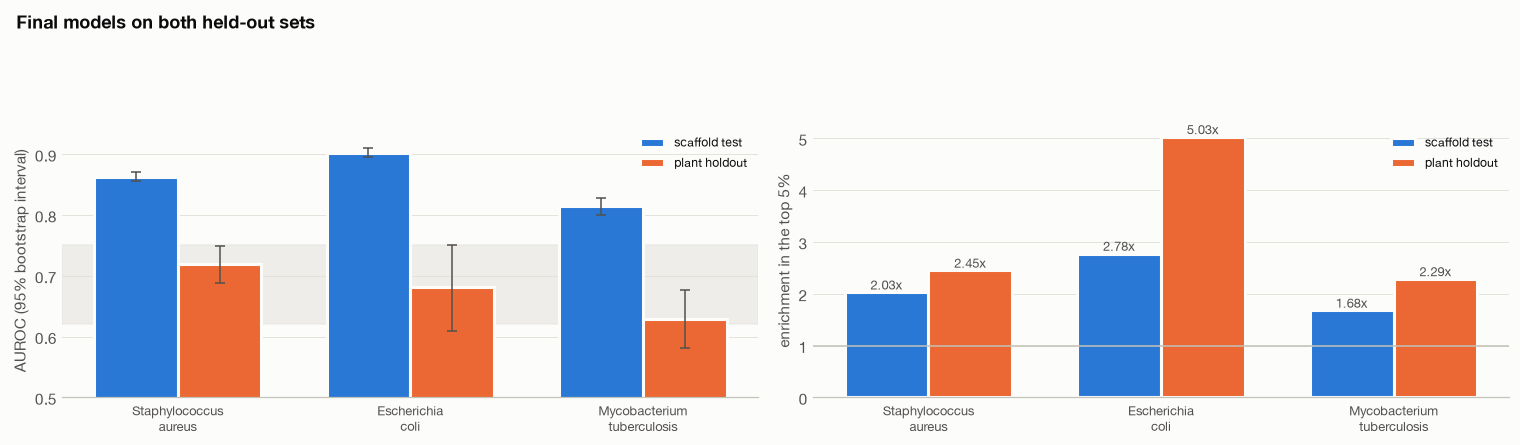

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
x = np.arange(len(CONFIG["pathogens"]))
width = 0.36
for i, name in enumerate(("test", "plant")):
    tag = "scaffold test" if name == "test" else "plant holdout"
    aurocs = [results.loc[(o, name), "auroc"] for o in CONFIG["pathogens"]]
    lo = [results.loc[(o, name), "auroc"] - results.loc[(o, name), "auroc_lo"]
          for o in CONFIG["pathogens"]]
    hi = [results.loc[(o, name), "auroc_hi"] - results.loc[(o, name), "auroc"]
          for o in CONFIG["pathogens"]]
    axes[0].bar(x + (i - 0.5) * width, aurocs, width=width, yerr=[lo, hi], capsize=3,
                color=viz.SERIES[i], edgecolor=viz.SURFACE, linewidth=2,
                error_kw=dict(ecolor=viz.INK_SECONDARY, lw=1), label=tag)
    enrich = [results.loc[(o, name), "enrichment_top_5pct"] for o in CONFIG["pathogens"]]
    axes[1].bar(x + (i - 0.5) * width, enrich, width=width, color=viz.SERIES[i],
                edgecolor=viz.SURFACE, linewidth=2, label=tag)
    for xi, v in zip(x + (i - 0.5) * width, enrich):
        axes[1].text(xi, v, f"{v:.2f}x", ha="center", va="bottom", fontsize=8.5,
                     color=viz.INK_SECONDARY)
axes[0].axhspan(0.62, 0.75, color=viz.GRID, alpha=0.5, zorder=0)
axes[0].set_ylim(0.5, 0.95)
axes[0].set_ylabel("AUROC (95% bootstrap interval)")
axes[1].axhline(1.0, color=viz.AXIS, linewidth=1)
axes[1].set_ylabel("enrichment in the top 5%")
for ax in axes:
    ax.set_xticks(x, [o.replace(" ", "\n") for o in CONFIG["pathogens"]], fontsize=8.5)
    ax.grid(axis="x", visible=False)
    ax.legend(fontsize=8)
fig.suptitle("Final models on both held-out sets", x=0.02, ha="left", fontweight="bold")
viz.save(fig, "04_held_out")
plt.show()

## 5a. An operating threshold, and what it is worth

A ranking becomes a decision when someone picks a cut-off. The threshold is chosen **on the
validation partition**: the one maximising precision subject to a recall floor, falling back to
the MCC-maximising threshold if that floor cannot be reached. It is then applied unchanged to both
held-out sets.

Threshold-dependent numbers measured on the partition that chose the threshold are optimistic by
construction. The validation row is shown for that reason, so the drop to the held-out rows is
visible rather than implied.

In [14]:
threshold_rows = []
for organism in CONFIG["pathogens"]:
    feature_name, _ = winners[organism]
    bundle, part = bundles[organism], parts[organism]
    X = featureset.matrix(bundle, feature_name)
    y = bundle["label"]
    probability = {n: calibrated[organism].predict_proba(X[part[n]])[:, 1]
                   for n in ("validation", "test", "plant")}
    threshold, rule = models.choose_threshold(
        y[part["validation"]], probability["validation"], recall_floor=CONFIG["recall_floor"])
    for name in ("validation", "test", "plant"):
        row = models.threshold_metrics(y[part[name]], probability[name], threshold)
        row.update({"pathogen": organism, "set": name, "rule": rule,
                    "chose the threshold": name == "validation"})
        threshold_rows.append(row)
    del X
thresholds = pd.DataFrame(threshold_rows).set_index(["pathogen", "set"])
thresholds[["threshold", "flagged", "precision", "recall", "f1", "mcc",
            "chose the threshold"]].style.format(
    {c: "{:.3f}" for c in ("threshold", "precision", "recall", "f1", "mcc")})

## 5b. Reliability, before and after calibration

Whether a predicted probability means what it says. Perfect calibration lies on the diagonal;
above it the model is under-confident and below it over-confident. The plant holdout is expected
to sit off the diagonal whatever the calibrator does, because Platt learns the mapping at the
validation base rate and the plant set has a different one.

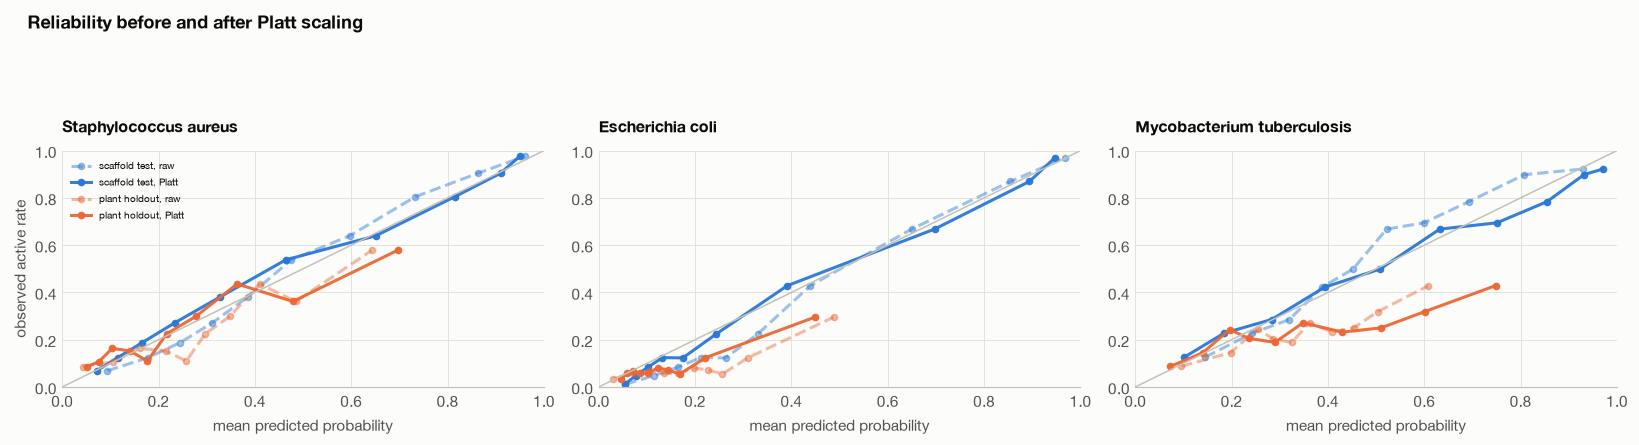

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, organism in zip(axes, CONFIG["pathogens"]):
    feature_name, _ = winners[organism]
    bundle, part = bundles[organism], parts[organism]
    X = featureset.matrix(bundle, feature_name)
    y = bundle["label"]
    for i, name in enumerate(("test", "plant")):
        raw = fitted[organism].predict_proba(X[part[name]])[:, 1]
        cal = calibrated[organism].predict_proba(X[part[name]])[:, 1]
        tag = "scaffold test" if name == "test" else "plant holdout"
        for curve, style, label in [(raw, "--", f"{tag}, raw"), (cal, "-", f"{tag}, Platt")]:
            table = models.reliability(y[part[name]], curve)
            if len(table):
                ax.plot(table.mean_predicted, table.observed, style, marker="o", markersize=4,
                        color=viz.SERIES[i], alpha=0.95 if style == "-" else 0.45, label=label)
    ax.plot([0, 1], [0, 1], color=viz.AXIS, linewidth=1)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xlabel("mean predicted probability")
    ax.set_title(organism, fontsize=10.5)
    del X
axes[0].set_ylabel("observed active rate")
axes[0].legend(fontsize=6.5)
fig.suptitle("Reliability before and after Platt scaling", x=0.02, ha="left", fontweight="bold")
viz.save(fig, "04_reliability")
plt.show()

## 5c. Does the censored negative class carry the result

A substantial minority of negatives rest only on `>` measurements, the share per pathogen
being printed in notebook 02, which say a compound failed above
some concentration rather than giving a value. If those rows near the threshold were driving the
score, the model would partly be learning which concentrations people chose to test at. This drops
every compound whose only evidence is a censored measurement within a factor of two of the
threshold, refits nothing, and rescores.

In [16]:
sensitivity_rows = []
for organism in CONFIG["pathogens"]:
    feature_name, _ = winners[organism]
    bundle, part = bundles[organism], parts[organism]
    X = featureset.matrix(bundle, feature_name)
    y = bundle["label"]
    rows = pd.read_parquet(
        data.PROCESSED / f"02_labelled_{curation.slug(organism)}.parquet",
        columns=["skeleton", "censored_only", "nearest_censored_um"],
    )
    flagged = set(rows.loc[
        rows.censored_only.fillna(False)
        & rows.nearest_censored_um.between(CONFIG["threshold_um"] / 2,
                                           CONFIG["threshold_um"] * 2), "skeleton"])
    for name in ("test", "plant"):
        index = part[name]
        scores = calibrated[organism].predict_proba(X[index])[:, 1]
        full = models.roc_auc_score(y[index], scores)
        keep = ~pd.Series(bundle["skeleton"][index]).isin(flagged).to_numpy()
        reduced = (models.roc_auc_score(y[index][keep], scores[keep])
                   if len(set(y[index][keep])) > 1 else np.nan)
        sensitivity_rows.append({
            "pathogen": organism, "set": name, "AUROC, all": full,
            "AUROC, censored-near-threshold dropped": reduced,
            "AUROC shift": reduced - full,
            "compounds dropped": int((~keep).sum()),
        })
    del X
pd.DataFrame(sensitivity_rows).set_index(["pathogen", "set"]).style.format(
    {"AUROC, all": "{:.3f}", "AUROC, censored-near-threshold dropped": "{:.3f}",
     "AUROC shift": "{:+.3f}"})

## 6. Save, and record the runs

In [17]:
written = []
for organism in CONFIG["pathogens"]:
    slug = curation.slug(organism)
    feature_name, model_name = winners[organism]
    payload = {
        "organism": organism,
        "feature_set": feature_name,
        "model": model_name,
        "params": tuned[organism],
        "model_object": fitted[organism],
        "calibrator": calibrated[organism],
        # The operating point belongs with the model. Without it on disk, downstream code that
        # wants a threshold has only the holdout score files to work from, and three separate
        # call sites duly refitted the threshold on the holdout before this was added.
        "threshold": float(thresholds.loc[(organism, "validation"), "threshold"]),
        "threshold_rule": str(thresholds.loc[(organism, "validation"), "rule"]),
        "threshold_partition": "validation",
    }
    path = data.PROCESSED / f"04_models_{slug}.pkl"
    path.write_bytes(pickle.dumps(payload))
    for name in ("validation", "test", "plant"):
        if (organism, name) in predictions:
            data.save_processed(predictions[(organism, name)], f"04_scores_{slug}_{name}")
    written.append({"pathogen": organism, "path": str(path.relative_to(ROOT)),
                    "MB": round(path.stat().st_size / 1e6, 1)})

    entry = ledger.record(
        f"model_{slug}",
        {
            "task": f"{organism} MIC, whole organism",
            "threshold_um": curation.PRIMARY_THRESHOLD_UM,
            "feature_set": feature_name,
            "model": model_name,
            "tuning": f"optuna TPE, {CONFIG['optuna_trials']} trials, validation AUROC",
            "tuning_source": tuning_source[organism],
            "data_fingerprint": data_fingerprint(organism),
            "threshold_um": curation.PRIMARY_THRESHOLD_UM,
            "params": tuned[organism],
            "calibration": CONFIG["calibration"],
            "recall_floor": CONFIG["recall_floor"],
            "bootstrap_repeats": CONFIG["bootstrap_repeats"],
            "threshold_rule": str(thresholds.loc[(organism, "validation"), "rule"]),
            "split": "scaffold group split, plant-derived compounds held out of training",
        },
        {
            "validation_auroc": tuned_value(organism),
            "test_auroc": results.loc[(organism, "test"), "auroc"],
            "test_auroc_lo": results.loc[(organism, "test"), "auroc_lo"],
            "test_auroc_hi": results.loc[(organism, "test"), "auroc_hi"],
            "test_auprc": results.loc[(organism, "test"), "auprc"],
            "test_p_at_10pct": results.loc[(organism, "test"), "precision_top_10pct"],
            "plant_auroc": results.loc[(organism, "plant"), "auroc"],
            "plant_auroc_lo": results.loc[(organism, "plant"), "auroc_lo"],
            "plant_auroc_hi": results.loc[(organism, "plant"), "auroc_hi"],
            "plant_auprc": results.loc[(organism, "plant"), "auprc"],
            "plant_auprc_lo": results.loc[(organism, "plant"), "auprc_lo"],
            "plant_auprc_hi": results.loc[(organism, "plant"), "auprc_hi"],
            "plant_p_at_10pct": results.loc[(organism, "plant"), "precision_top_10pct"],
            "plant_p_at_10pct_lo": results.loc[(organism, "plant"), "precision_top_10pct_lo"],
            "plant_p_at_10pct_hi": results.loc[(organism, "plant"), "precision_top_10pct_hi"],
            "plant_precision_top_5pct": results.loc[(organism, "plant"), "precision_top_5pct"],
            "plant_enrichment_top_5pct": results.loc[(organism, "plant"), "enrichment_top_5pct"],
            "plant_share_of_ceiling": results.loc[(organism, "plant"), "share_of_ceiling"],
            "plant_base_rate": results.loc[(organism, "plant"), "base_rate"],
            "threshold": float(thresholds.loc[(organism, "plant"), "threshold"]),
            "plant_precision_at_threshold": float(
                thresholds.loc[(organism, "plant"), "precision"]),
            "plant_recall_at_threshold": float(thresholds.loc[(organism, "plant"), "recall"]),
            "plant_mcc_at_threshold": float(thresholds.loc[(organism, "plant"), "mcc"]),
        },
        note="tuned model, scored on the scaffold test set and the plant holdout",
    )
    print(f"{organism}: ledger {entry['id']}")
pd.DataFrame(written).set_index("pathogen")

Staphylococcus aureus: ledger 2026-11-05T15:55:11_model_staphylococcus_aureus


Escherichia coli: ledger 2026-11-05T15:55:12_model_escherichia_coli


Mycobacterium tuberculosis: ledger 2026-11-05T15:55:12_model_mycobacterium_tuberculosis


,path,MB
pathogen,,
Staphylococcus aureus,data/processed/04_models_staphylococcus_aureus...,581.0
Escherichia coli,data/processed/04_models_escherichia_coli.pkl,414.7
Mycobacterium tuberculosis,data/processed/04_models_mycobacterium_tubercu...,201.3


## 7. What 05 is getting

Filled in from the numbers above after the run.